### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

In [2]:
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6,
    "axes.axisbelow": True, "font.size": 10})

In [3]:
kes = mt.FuncFormatter(lambda v, p: f"{v:,.0f}")

### Import data

In [4]:
shop = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\shop_data.csv", parse_dates=["InvoiceDate"])
inflation = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\inflation_data.csv",  parse_dates=["Period"])
holidays = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\holidays_data.csv", parse_dates=["Date"])
cpi = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\cpi_data.csv", parse_dates=["Period"])
population = pd.read_csv(r"C:\Users\Glemba\Desktop\Kenyan retail analysis\cleaned_data\population_data.csv", dtype=str, keep_default_na=False, encoding="utf-8-sig")

print(
    "Shop",
    shop.shape,
    "| dates", shop.InvoiceDate.min().date(),
    "-",
    shop.InvoiceDate.max().date()
)
print(
    "cpi",
    cpi.shape,
    "| inflation",
    inflation.shape,
    "| Holidays",
    holidays.shape,
    "| Population",
    population.shape
)

shop["Revenue"] = shop["TotalPrice"]

print(
    shop[["Quantity","UnitPrice", "TotalPrice"]].describe().round(2)
)

Shop (1500, 9) | dates 2023-01-01 - 2023-12-31
cpi (213, 8) | inflation (201, 8) | Holidays (84, 5) | Population (42507, 13)
       Quantity  UnitPrice  TotalPrice
count   1500.00    1500.00     1500.00
mean       1.00     147.60      147.19
std        0.49      97.61      116.56
min        0.00      29.01        0.00
25%        1.00      59.60       57.09
50%        1.00     124.37      121.44
75%        1.00     215.28      217.40
max        5.00     366.89     1152.40


### Build the county table from population_data

In [5]:
population = population.iloc[:, [0, 2, 5]]                      # area name, sex, observation
population.columns = ["Area", "Sex", "Population"]
population["Area"] = population["Area"].str.strip().str.upper()
population["Population"] = pd.to_numeric(population["Population"])

# the file stores Male, Female, Total as 3 consecutive rows per area -> one row per area
assert (population["Sex"].to_numpy().reshape(-1, 3) == ["Male", "Female", "Total"]).all()
census = pd.DataFrame({
    "Area": population["Area"].to_numpy()[::3],
    "MalePopulation": population["Population"].to_numpy()[::3],
    "FemalePopulation": population["Population"].to_numpy()[1::3],
    "TotalPopulation": population   ["Population"].to_numpy()[2::3],
})

COUNTIES = ["MOMBASA","KWALE","KILIFI","TANA RIVER","LAMU","TAITA/TAVETA","GARISSA","WAJIR","MANDERA","MARSABIT",
 "ISIOLO","MERU","THARAKA NITHI","EMBU","KITUI","MACHAKOS","MAKUENI","NYANDARUA","NYERI","KIRINYAGA","MURANGA","KIAMBU",
 "TURKANA","WEST POKOT","SAMBURU","TRANS NZOIA","UASIN GISHU","ELGEYO/MARAKWET","NANDI","BARINGO","LAIKIPIA","NAKURU",
 "NAROK","KAJIADO","KERICHO","BOMET","KAKAMEGA","VIHIGA","BUNGOMA","BUSIA","SIAYA","KISUMU","HOMA BAY","MIGORI","KISII",
 "NYAMIRA","NAIROBI"]

# names repeat (e.g. KIAMBU is also a ward), so keep the largest row per name = the county itself
county = (census[census["Area"].isin(COUNTIES)]
          .sort_values("TotalPopulation", ascending=False)
          .drop_duplicates("Area")
          .rename(columns={"Area": "County"})
          .reset_index(drop=True))

# checks
assert len(county) == 47
assert county.TotalPopulation.sum() == census.loc[census.Area == "KENYA", "TotalPopulation"].iloc[0]
county.head()

,County,MalePopulation,FemalePopulation,TotalPopulation
0,NAIROBI,2192452,2204376,4397073
1,KIAMBU,1187146,1230454,2417735
2,NAKURU,1077272,1084835,2162202
3,KAKAMEGA,897133,970406,1867579
4,BUNGOMA,812146,858389,1670570


### Join shop data and population data

In [6]:
# map each shop town to its county
LOCATION_TO_COUNTY = {
    "Nairobi": "NAIROBI", "Roysambu": "NAIROBI", "Umoja": "NAIROBI",
    "Thika": "KIAMBU", "Ruiru": "KIAMBU", "Ruaka": "KIAMBU",
    "Kitengela": "KAJIADO", "Rongai": "KAJIADO",   # Ongata Rongai; change to "NAKURU" if you mean Rongai in Nakuru
}
shop["County"] = shop["Location"].str.strip().str.title().map(LOCATION_TO_COUNTY)
assert shop["County"].notna().all(), shop.loc[shop.County.isna(), "Location"].unique()

# merge and check
cols = ["County", "TotalPopulation", "MalePopulation", "FemalePopulation"]
merged = shop.merge(
    county[cols].rename(columns={"TotalPopulation": "County_TotalPopulation",
                                 "MalePopulation": "County_MalePopulation",
                                 "FemalePopulation": "County_FemalePopulation"}),
    on="County", how="left", validate="m:1")        # many shop rows -> one county row

assert len(merged) == len(shop)                     # join must not add or drop rows
assert merged["County_TotalPopulation"].notna().all()      # every order found its county
merged[["Location", "County", "County_TotalPopulation"]].drop_duplicates()

,Location,County,County_TotalPopulation
0,Umoja,NAIROBI,4397073
1,Nairobi,NAIROBI,4397073
2,Roysambu,NAIROBI,4397073
3,Ruiru,KIAMBU,2417735
8,Rongai,KAJIADO,1117840
9,Thika,KIAMBU,2417735
18,Kitengela,KAJIADO,1117840
41,Ruaka,KIAMBU,2417735


In [21]:
shop.head()

,InvoiceNo,CustomerID,Product,Quantity,UnitPrice,TotalPrice,InvoiceDate,Location,CustomerType,Revenue,County,Date,PayWindow
0,ORD10000,CUST1076,Sanitary Towels (Pack),1,153.60,153.60,2023-02-17,Umoja,Regular,153.60,NAIROBI,2023-02-17,False
1,ORD10001,CUST1075,Bread (400g),1,52.55,52.55,2023-02-09,Nairobi,Regular,52.55,NAIROBI,2023-02-09,False
2,ORD10002,CUST1020,Milk (500ml),1,44.20,44.20,2023-02-01,Roysambu,Regular,44.20,NAIROBI,2023-02-01,True
3,ORD10003,CUST1181,Sanitary Towels (Pack),1,250.33,250.33,2023-02-22,Ruiru,Budget,250.33,KIAMBU,2023-02-22,False
4,ORD10004,CUST1079,Sugar (1kg),1,132.24,132.24,2023-04-13,Nairobi,Budget,132.24,NAIROBI,2023-04-13,False


### Shop data Distributions

In [7]:
print("Zero TotalPrice:", (shop.TotalPrice <= 0).sum())
print(shop[shop.TotalPrice <= 0][["Quantity","UnitPrice","TotalPrice"]].head())

Zero TotalPrice: 78
    Quantity  UnitPrice  TotalPrice
12         0     270.96         0.0
32         0      69.94         0.0
34         0     208.38         0.0
35         0      59.89         0.0
47         0      57.99         0.0


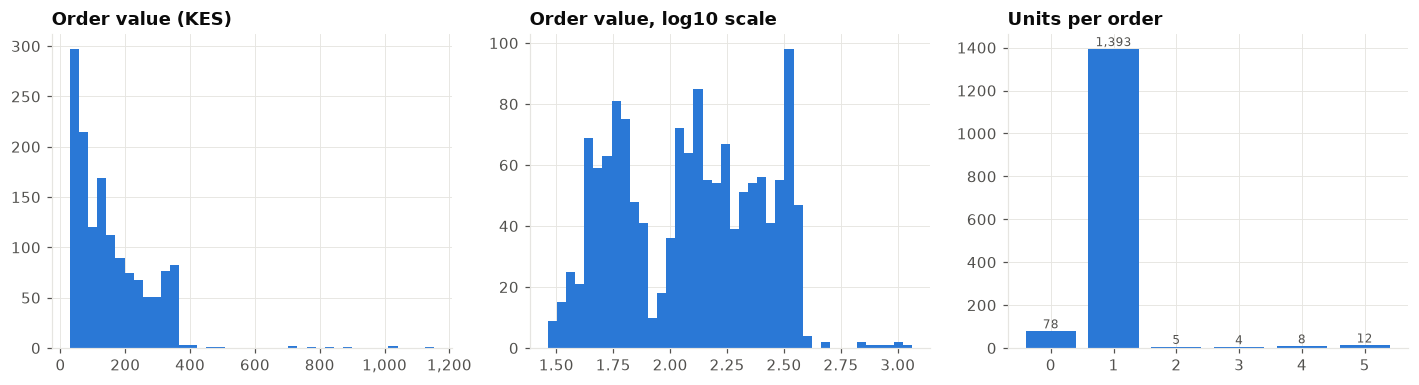

Quantity share: {0: 5.2, 1: 92.87, 2: 0.33, 3: 0.27, 4: 0.53, 5: 0.8}
skew order value: 2.09 | Median 121.44 | Mean 155
bulk orders (quantity>=4): 20 = 1.3% of orders, 4.9% of revenue


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))

shop_pos = shop[shop.TotalPrice > 0]

#plot 0 - order value distribution
ax[0].hist(shop_pos.TotalPrice, bins=40, color=BLUE)
ax[0].set_title("Order value (KES)")
ax[0].xaxis.set_major_formatter(kes)

#plot 1 - order value distribution(log-transformed)
ax[1].hist(np.log10(shop_pos.TotalPrice), bins=40, color=BLUE)
ax[1].set_title("Order value, log10 scale")

#plot 2 - units per order
upo = shop.Quantity.value_counts().sort_index()
ax[2].bar(upo.index.astype(str), upo.values, color=BLUE)
ax[2].set_title("Units per order")
for i, v in enumerate(upo.values):
    ax[2].text(
        i,
        v,
        f"{v:,}",
        ha="center",
        va="bottom",
        fontsize=8,
        color=MUTED
        )
plt.tight_layout()
plt.show()

print(
    "Quantity share:",
    (shop.Quantity.value_counts(normalize=True)
    .sort_index() * 100)
    .round(2)
    .to_dict()
    )
print(
    "skew order value:",
    round(stats.skew(shop_pos.TotalPrice), 2),
    "| Median",
    shop.TotalPrice.median(),
    "| Mean",
    round(shop_pos.TotalPrice.mean())
)
bulk = shop[shop.Quantity >=4]
print(f"bulk orders (quantity>=4): {len(bulk)} = {len(bulk)/len(shop):.1%} of orders, {bulk.Revenue.sum()/shop.Revenue.sum():.1%} of revenue")

C:\Users\Glemba\AppData\Local\Temp\ipykernel_21856\1755180759.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


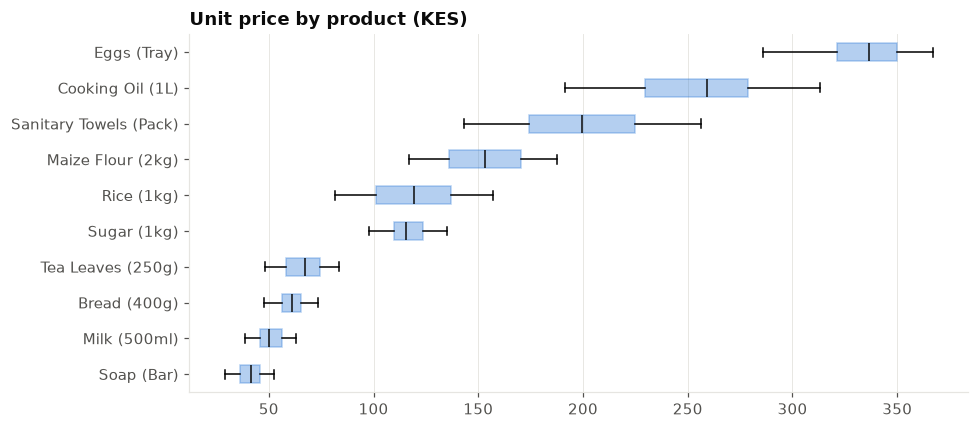

                        median    std     min     max   cv_%
Product                                                     
Soap (Bar)               41.73   5.98   29.01   52.48  14.57
Milk (500ml)             50.29   6.32   38.77   62.85  12.41
Bread (400g)             60.98   6.04   47.91   73.26   9.90
Tea Leaves (250g)        67.33   9.00   48.43   83.29  13.49
Sugar (1kg)             115.49   8.82   97.76  135.30   7.55
Rice (1kg)              119.22  20.44   81.44  157.05  17.19
Maize Flour (2kg)       153.03  19.08  117.15  187.63  12.41
Sanitary Towels (Pack)  199.64  29.57  143.29  256.09  14.73
Cooking Oil (1L)        259.38  30.37  191.48  313.34  11.87
Eggs (Tray)             336.46  19.28  285.75  366.89   5.77


In [9]:
order = shop.groupby("Product").UnitPrice.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(
    [shop[shop.Product == p].UnitPrice for p in order],
    vert=False,
    tick_labels=order,
    patch_artist=True,
    boxprops=dict(
        facecolor=BLUE,
        alpha=.35,
        edgecolor=BLUE
    ),
    medianprops=dict(color=INK),
    flierprops=dict(
        markersize=3,
        markerfacecolor=ORANGE,
        markeredgecolor=ORANGE
    ))
ax.set_title("Unit price by product (KES)")
ax.xaxis.set_major_formatter(kes)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

pp = shop.groupby("Product").UnitPrice.agg(["median", "std", "min", "max"])
pp["cv_%"] = (100 * pp["std"] / shop.groupby("Product").UnitPrice.mean()).round(2)
print(pp.round(2).sort_values("median"))


### Trends over time

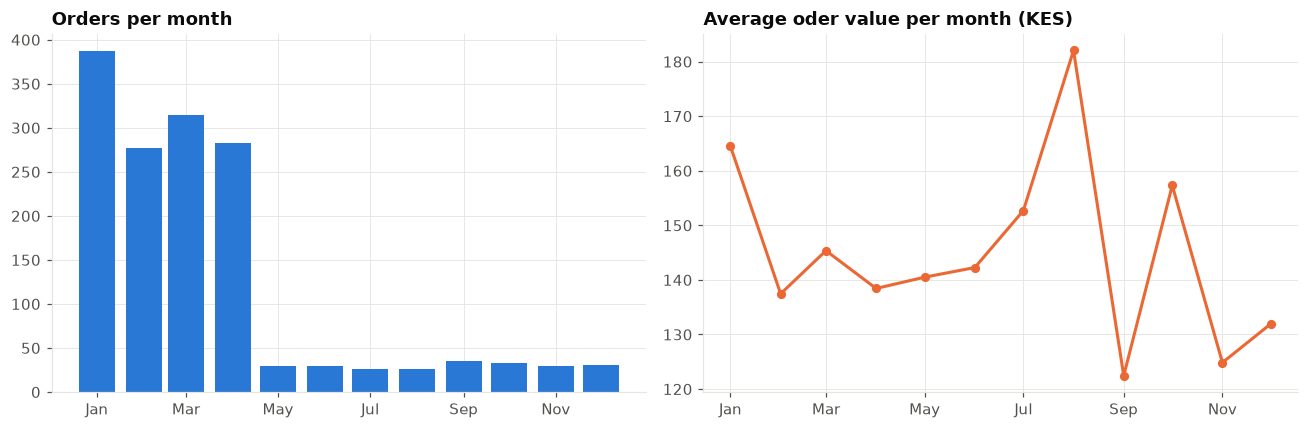

            Orders   Revenue  Customers     AOV
Date                                           
2023-01-01     387  63655.31        193  164.48
2023-02-01     277  38075.07        171  137.46
2023-03-01     314  45642.41        192  145.36
2023-04-01     283  39177.54        171  138.44
2023-05-01      30   4215.10         28  140.50
2023-06-01      29   4125.80         26  142.27
2023-07-01      26   3970.21         24  152.70
2023-08-01      26   4733.36         23  182.05
2023-09-01      35   4285.28         34  122.44
2023-10-01      33   5191.33         31  157.31
2023-11-01      29   3620.59         25  124.85
2023-12-01      31   4091.49         29  131.98

Jan-Apr = 84.1% of all orders; avg orders/month Jan-Apr 315 vs May-Dec 30


In [10]:
shop["Date"] = shop["InvoiceDate"].dt.normalize()

# Monthly aggregation
m = shop.groupby(shop.Date.dt.to_period("M")).agg(
    Orders=("InvoiceNo", "count"),
    Revenue=("Revenue", "sum"),
    Customers=("CustomerID", "nunique"),
    AOV=("Revenue", "mean")
)
m.index = m.index.to_timestamp()

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(
    m.index,
    m.Orders,
    width=24,
    color=BLUE
)
ax[0].set_title("Orders per month")

ax[1].plot(
    m.index,
    m.AOV,
    color=ORANGE,
    lw=2,
    marker="o",
    ms=5
)
ax[1].set_title("Average oder value per month (KES)")
for a in ax:
     a.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.tight_layout()
plt.show()

# Printed analysis
print(m.round(2))
# full monthly table
h1 = m.loc[:"2023-04-30"].Orders.sum()
print(f"\nJan-Apr = {h1/m.Orders.sum():.1%} of all orders; avg orders/month Jan-Apr {m.loc[:'2023-04-30'].Orders.mean():.0f} vs May-Dec {m.loc['2023-05-01':].Orders.mean():.0f}")

Days with zero orders: 94 of 365 | max/day 24


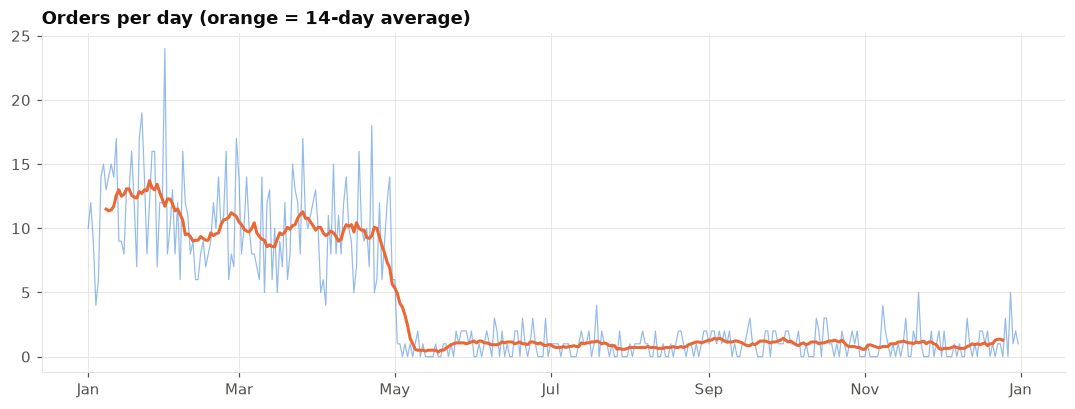

In [11]:
d = shop.groupby("Date").size().reindex(pd.date_range("2023-01-01", "2023-12-31"), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    d.index,
    d.values,
    color=BLUE,
    lw=.8,
    alpha=.5
)
ax.plot(
    d.index,
    d.rolling(14, center=True)
    .mean(),
    color=ORANGE,
    lw=2
)
ax.set_title("Orders per day (orange = 14-day average)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

print(
    "Days with zero orders:",
    int((d == 0).sum()), "of",
    len(d),
    "| max/day",
    d.max()
)

### Seasonality and calender effects

           Orders     AOV  Orders_per_cal_day
Date                                         
Monday        203  148.02                3.90
Tuesday       229  130.98                4.40
Wednesday     214  154.42                4.12
Thursday      205  153.34                3.94
Friday        226  146.79                4.35
Saturday      206  147.16                3.96
Sunday        217  151.02                4.09
Weekday uniformity chi2 p = 0.8085
           Orders     AOV  Days  Orders_per_day
PayWindow                                      
False        1024  146.16   252            4.06
True          476  149.41   113            4.21


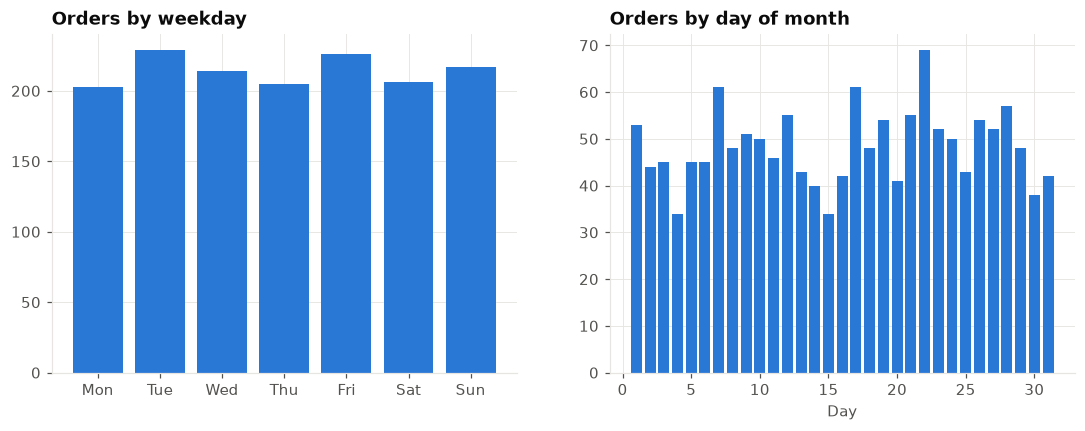

In [12]:
# weekday effect
wd = shop.groupby(shop.Date.dt.day_name()).agg(Orders=("InvoiceNo", "count"), AOV=("Revenue", "mean")).reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])

n_days = pd.Series(pd.date_range("2023-01-01", "2023-12-31").day_name()).value_counts()
wd["Orders_per_cal_day"] = wd.Orders / n_days.reindex(wd.index)

dom = shop.groupby(shop.Date.dt.day).size()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(wd.index.str[:3], wd.Orders, color=BLUE)
ax[0].set_title("Orders by weekday")

ax[1].bar(dom.index, dom.values, color=BLUE)
ax[1].set_title("Orders by day of month")
ax[1].set_xlabel("Day")

# chi square test (null hypothesis = orders are uniform across weekdays)
chi = stats.chisquare(wd.Orders)
print(wd.round(2))
print("Weekday uniformity chi2 p =", round(chi.pvalue, 4))

# pay window effect
shop["PayWindow"] = (shop.Date.dt.day >= 25) | (shop.Date.dt.day <=3)
pw = shop.groupby("PayWindow").agg(Orders=("InvoiceNo", "count"), AOV=("Revenue", "mean"))
all_days = pd.Series(pd.date_range("2023-01-01", "2023-12-31"))
pw_cal = (all_days.dt.day >= 25) | (all_days.dt.day <= 3)
pw["Days"] = [(~pw_cal).sum(), pw_cal.sum()]
pw["Orders_per_day"] = pw.Orders / pw.Days 
print(pw.round(2))


               mean  count
Window                    
holiday        5.33     12
1-3 days away  3.69     59
4-7 days away  3.31     58
8+ days away   4.35    236
Jan-Apr holiday days: 0 {False: 10.51}
MannwhitneyuResult(statistic=np.float64(nan), pvalue=np.float64(nan))


C:\Users\Glemba\AppData\Local\Temp\ipykernel_21856\979449535.py:28: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  print(stats.mannwhitneyu(jb[jb.IsHoliday].Orders, jb[~jb.IsHoliday].Orders))


Text(0.0, 1.0, 'Average orders per day, by distance to a public holiday')

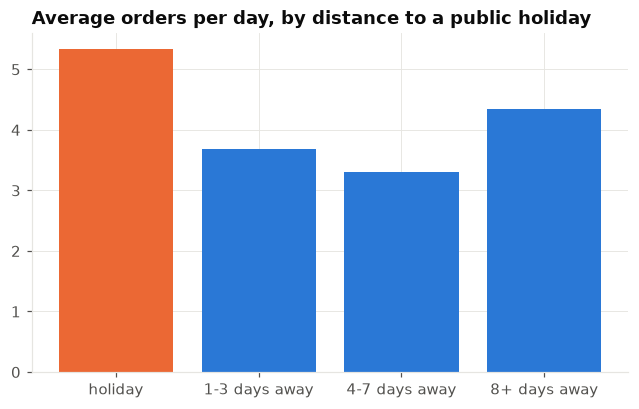

In [13]:
# prep holiday list + daily sales
hol_23 = holidays[holidays.Year == 2023][["Date", "Holiday Name", "Type"]]

# filter holidays to just 2023, keep 3 columns
days = pd.DataFrame({"Date": pd.date_range("2023-01-01", "2023-12-31")})
days["Orders"] = days.Date.map(shop.groupby("Date").size()).fillna(0)
days["IsHoliday"] = days.Date.isin(hol_23)

# distance to nearest holiday
near = lambda x: min(abs((x - h).days) for h in hol_23.Date)
days["DaystoHoliday"] = days.Date.map(near)
days["Window"] = pd.cut(
    days.DaystoHoliday,
    [-1, 0, 3, 7, 400],
    labels=[
        "holiday",
        "1-3 days away",
        "4-7 days away",
        "8+ days away"
    ]
)
w = days.groupby("Window", observed=True).Orders.agg(["mean", "count"]).round(2)
print(w)

# statistical test(compare Jan-Apr only, so the volume drop after April doesn't confound the test)
jb = days[days.Date <= "2023-04-30"]
print("Jan-Apr holiday days:", jb.IsHoliday.sum(), jb.groupby("IsHoliday").Orders.mean().round(2).to_dict())
print(stats.mannwhitneyu(jb[jb.IsHoliday].Orders, jb[~jb.IsHoliday].Orders))

# plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(w.index.astype(str), w["mean"], color=[ORANGE, BLUE, BLUE, BLUE])
ax.set_title("Average orders per day, by distance to a public holiday")

### Store, towns and counties

           Orders   Revenue  Customers     AOV   County      Pop  \
Location                                                           
Nairobi       485  71526.60         96  147.48  NAIROBI  4397073   
Thika         215  31476.26         44  146.40   KIAMBU  2417735   
Ruiru         179  28075.80         34  156.85   KIAMBU  2417735   
Kitengela     186  27567.13         36  148.21  KAJIADO  1117840   
Roysambu      162  24076.72         31  148.62  NAIROBI  4397073   
Rongai        141  19087.94         25  135.38  KAJIADO  1117840   
Ruaka          77  12373.65         19  160.70   KIAMBU  2417735   
Umoja          55   6599.39         14  119.99  NAIROBI  4397073   

           RevenueShare_%  OrdersPerCustomer  
Location                                      
Nairobi             32.40               5.05  
Thika               14.26               4.89  
Ruiru               12.72               5.26  
Kitengela           12.49               5.17  
Roysambu            10.91            

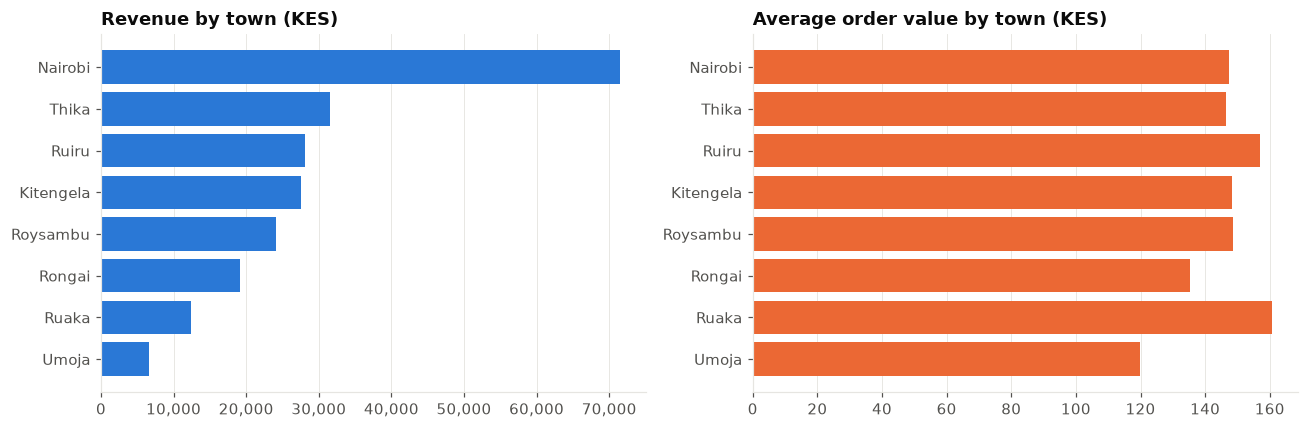

Kruskal-Wallis order value across towns p = 0.359


In [33]:
# aggregation
loc = merged.groupby("Location").agg(
    Orders=("InvoiceNo", "count"),
    Revenue=("Revenue", "sum"),
    Customers=("CustomerID", "nunique"),
    AOV=("Revenue", "mean"),
    County=("County", "first"),
    Pop=("County_TotalPopulation", "first"),
).sort_values("Revenue", ascending=False)

loc["RevenueShare_%"] = (100 * loc.Revenue / loc.Revenue.sum()).round(2)
loc["OrdersPerCustomer"] = (loc.Orders / loc.Customers).round(2)
print(loc.round(2))

# plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(loc.index[::-1], loc.Revenue[::-1], color=BLUE)
ax[0].set_title("Revenue by town (KES)")
ax[0].xaxis.set_major_formatter(kes); ax[0].grid(axis="y", visible=False)

ax[1].barh(loc.index[::-1], loc.AOV[::-1], color=ORANGE)
ax[1].set_title("Average order value by town (KES)")
ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

# statistical test
groups = [merged.loc[merged.Location == town, "Revenue"] for town in loc.index]
print("Kruskal-Wallis order value across towns p =", round(stats.kruskal(*groups).pvalue, 3))

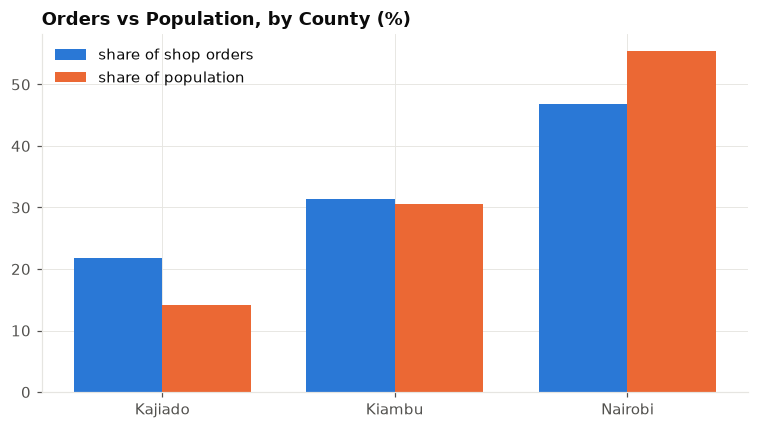

In [ ]:
# county aggregation
cnty = merged.groupby("County").agg(
    Orders=("InvoiceNo", "count"),
    Revenue=("Revenue", "sum"),
    Customers=("CustomerID", "nunique"),
    Pop=("County_TotalPopulation", "first"),
).reset_index()

# per-capita and share metrics
cnty["Orders_per_10k_residents"] = (1e4 * cnty.Orders / cnty.Pop).round(2)
cnty["Revenue_per_resident"] = (cnty.Revenue / cnty.Pop).round(4)
cnty["Share_of_orders_%"] = (100 * cnty.Orders / cnty.Orders.sum()).round(1)
cnty["Share_of_population_%"] = (100 * cnty.Pop / cnty.Pop.sum()).round(1)
cnty

# plot - side by side comparison
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(cnty))
wd_ = .38
ax.bar(
    x - wd_/2,
    cnty["Share_of_orders_%"],
    wd_,
    color=BLUE,
    label="share of shop orders"
)
ax.bar(
    x + wd_/2,
    cnty["Share_of_population_%"],
    wd_,
    color=ORANGE,
    label="share of population"
)
ax.set_xticks(x)
ax.set_xticklabels(cnty.County.str.title())
ax.legend(frameon=False)
ax.set_title("Orders vs Population, by County (%)")
plt.tight_layout()
plt.show()


### Products

Price vs Orders Spearman: SignificanceResult(statistic=np.float64(0.6606060606060605), pvalue=np.float64(0.03758837757140934))


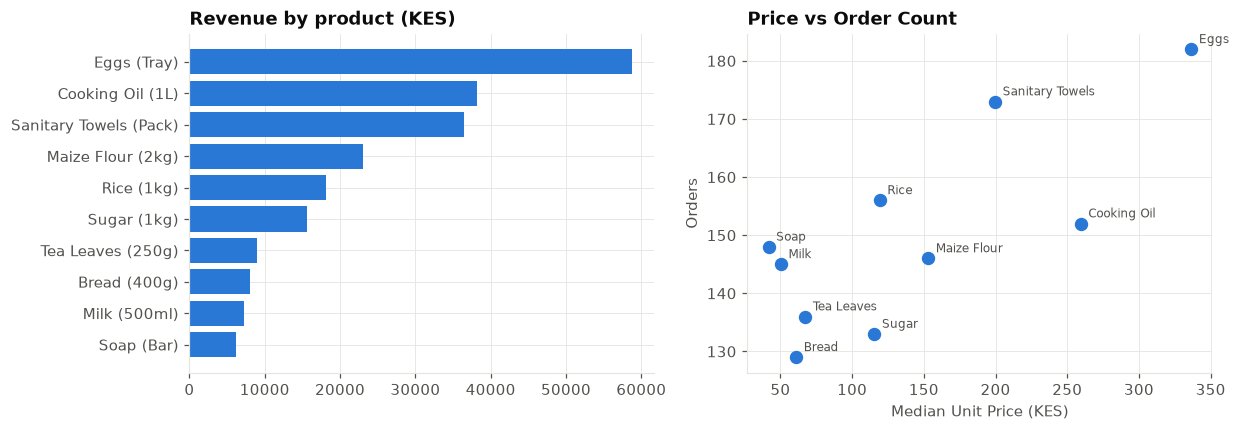

In [30]:
# product aggregation
pr = shop.groupby("Product").agg(
    Orders=("InvoiceNo", "count"),
    Units=("Quantity", "sum"),
    Revenue=("Revenue", "sum"),
    MedianPrice=("UnitPrice", "median")
).sort_values("Revenue", ascending=False)
pr["RevenueShare_%"] = (100 * pr.Revenue / pr.Revenue.sum()).round(2)
pr["OrderShare_%"] = (100 * pr.Orders / pr.Orders.sum()).round(2)
pr["CumulativeRev_%"] = pr["RevenueShare_%"].cumsum().round(2)

# plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(pr.index[::-1], pr.Revenue[::-1], color=BLUE)
ax[0].set_title("Revenue by product (KES)")

ax[1].scatter(pr.MedianPrice, pr.Orders, s=60, color=BLUE)
for n, r in pr.iterrows():
    ax[1].annotate(
        n.split(" (")[0],
        (r.MedianPrice,
        r.Orders),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
        color=MUTED
    )
ax[1].set_xlabel("Median Unit Price (KES)")
ax[1].set_ylabel("Orders")
ax[1].set_title("Price vs Order Count")

# test
print("Price vs Orders Spearman:", stats.spearmanr(pr.MedianPrice, pr.Orders))

Products mix differs by town? chi2 p = 0.126


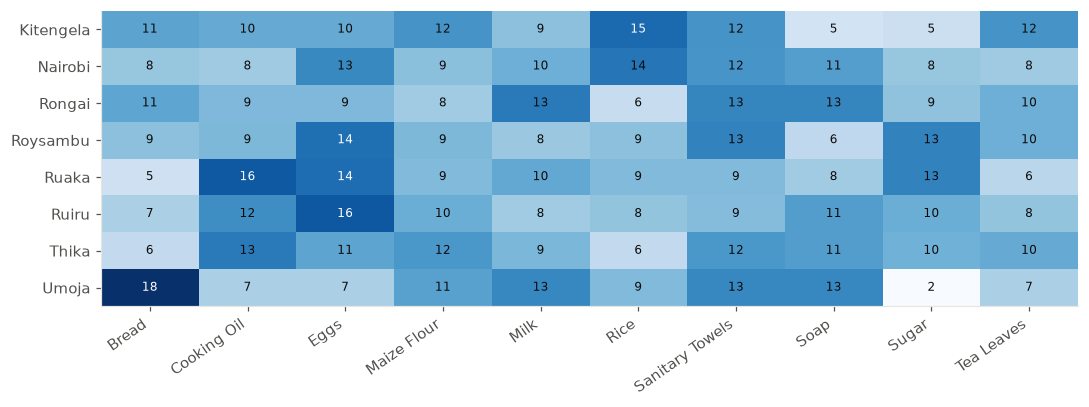

In [39]:
# table
pt = pd.crosstab(shop.Location, shop.Product, normalize="index") * 100

# statistical test
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(shop.Location, shop.Product))
print("Products mix differs by town? chi2 p =", round(p, 3))

# heatmap
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(pt.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(pt.shape[1]))
ax.set_xticklabels([c.split(" (")[0] for c in pt.columns], rotation=35, ha="right")
ax.set_yticks(range(pt.shape[0]))
ax.set_yticklabels(pt.index)
ax.grid(False)
for i in range(pt.shape[0]):
    for j in range(pt.shape[1]):
        ax.text(
            j,
            i,
            f"{pt.values[i,j]:.0f}",
            ha="center",
            va="center", 
            fontsize=8, 
            color=INK if pt.values[i, j] < 14 else "white"
        )
plt.tight_layout()
plt.show()


### Customer segments

              Orders  Customers    Revenue     AOV  MedianPrice  AvrgQntt  \
CustomerType                                                                
Budget           921        176  134923.67  146.50       128.52      0.95   
Premium          128         29   25189.96  196.80       112.34      1.60   
Regular          451         94   60669.86  134.52       119.97      0.95   

              Rev_share_%  Custmr_share_%  Order_per_custmr  
CustomerType                                                 
Budget              61.11           58.86              5.23  
Premium             11.41            9.70              4.41  
Regular             27.48           31.44              4.80  
Kruskal-Wallis unit price across segments p = 0.005529881048271738
Segment x town:
 CustomerType  Budget  Premium  Regular
Location                              
Kitengela      60.75     4.30    34.95
Nairobi        63.92     9.28    26.80
Rongai         58.87    19.15    21.99
Roysambu       65.43     

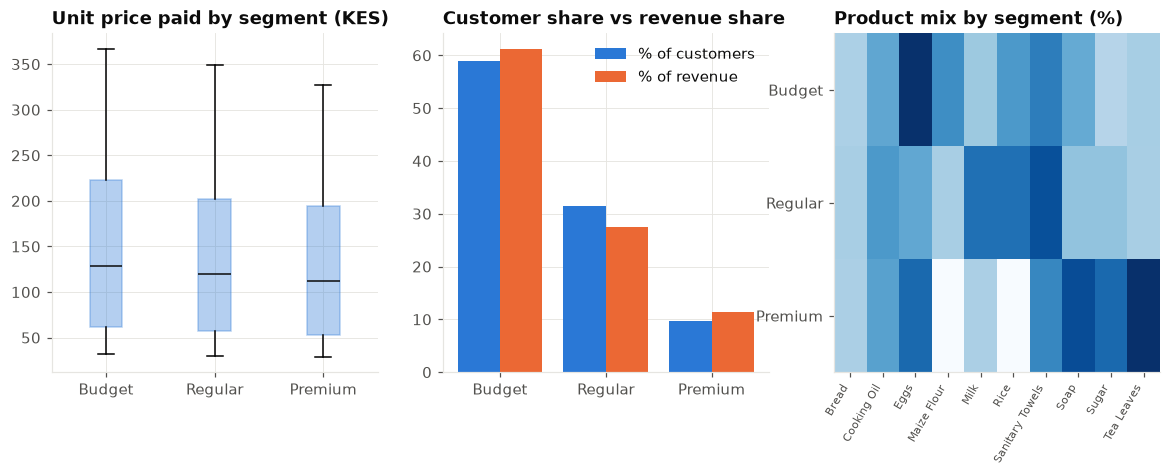

In [45]:
# segment table
sg = shop.groupby("CustomerType").agg(
    Orders=("InvoiceNo", "count"),
    Customers=("CustomerID", "nunique"),
    Revenue=("Revenue", "sum"),
    AOV=("Revenue", "mean"),
    MedianPrice=("UnitPrice", "median"),
    AvrgQntt=("Quantity", "mean")
)
sg["Rev_share_%"] = (100 * sg.Revenue / sg.Revenue.sum()).round(2)
sg["Custmr_share_%"] = (100 * sg.Customers / sg.Customers.sum()).round(2)
sg["Order_per_custmr"] = (sg.Orders / sg.Customers).round(2)

print(sg.round(2))

# three plots
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
cols = {
    "Budget": BLUE, 
    "Regular": ORANGE, 
    "Premium": AQUA
}
 
ordr = ["Budget", "Regular", "Premium"]

## boxplot - unit price
ax[0].boxplot(
    [shop[shop.CustomerType == s].UnitPrice for s in ordr],
    tick_labels=ordr,
    patch_artist=True,
    boxprops=dict(facecolor=BLUE, alpha=.35, edgecolor=BLUE),
    medianprops=dict(color=INK)
)
ax[0].set_title("Unit price paid by segment (KES)")

## share comparison
ax[1].bar(
    ordr,
    sg.loc[ordr, "Custmr_share_%"],
    width=.4,
    color=BLUE,
    label="% of customers"
)
ax[1].bar(
    np.arange(3) + .4,
    sg.loc[ordr, "Rev_share_%"],
    width=.4,
    color=ORANGE,
    label="% of revenue"
)
ax[1].set_xticks(np.arange(3) + .2)
ax[1].set_xticklabels(ordr)
ax[1].legend(frameon=False)
ax[1].set_title("Customer share vs revenue share")

## product mix by segment heatmap
mix = pd.crosstab(shop.CustomerType, shop.Product, normalize="index").loc[ordr] * 100

ax[2].imshow(
    mix.values,
    cmap="Blues",
    aspect="auto"
)
ax[2].set_xticks(range(10))
ax[2].set_xticklabels(
    [c.split(" (")[0] for c in mix.columns],
    rotation=60,
    ha="right",
    fontsize=7
)
ax[2].set_yticks(range(3))    
ax[2].set_yticklabels(ordr)
ax[2].grid(False) 
ax[2].set_title("Product mix by segment (%)")

# tests
print(
    "Kruskal-Wallis unit price across segments p =",
    stats.kruskal(*[shop[shop.CustomerType == s].UnitPrice for s in ordr]).pvalue
)
print(
    "Segment x town:\n",
    (pd.crosstab(
        shop.Location,
        shop.CustomerType,
        normalize="index") * 100).round(2)
)

# price paid vs product median -> do Premium customers pay more for the SAME product?
shop["ReltvPrice"] = shop.UnitPrice / shop.groupby("Product").UnitPrice.transform("median")

print(
    "Relative price to product median, by segment:\n",
    shop.groupby("CustomerType").ReltvPrice.agg(["mean", "median", "std"]).round(3)
)
print(
    "Kruskal-Wallis relative price p =",
    stats.kruskal(*[shop[shop.CustomerType == s].ReltvPrice for s in ordr]).pvalue
)


299 customers | top 20% (60) = 37.2% of revenue | one-order customers: 2.0% | median orders 5.0


Text(0.0, 1.0, 'Orders per customer')

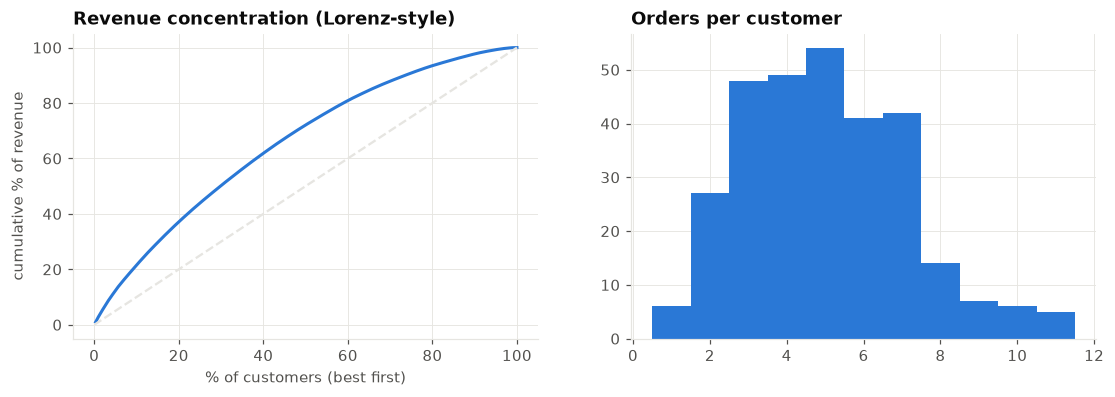

In [47]:
# customer aggregation
cu = shop.groupby("CustomerID").agg(
    Orders=("InvoiceNo", "count"), 
    Spend=("Revenue", "sum"), 
    Type=("CustomerType", "first")
).sort_values("Spend", ascending=False)

cu["cum_%"] = 100 * cu.Spend.cumsum() / cu.Spend.sum()
top20 = int(np.ceil(.2 * len(cu))) 

print(f"{len(cu)} customers | top 20% ({top20}) = {cu.Spend.head(top20).sum()/cu.Spend.sum():.1%} of revenue | one-order customers: {(cu.Orders==1).mean():.1%} | median orders {cu.Orders.median()}")

# plots
## revenue concentration(Lorenz-style)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(
    np.arange(1, len(cu) + 1) / len(cu) * 100, 
    cu["cum_%"], 
    color=BLUE, 
    lw=2
)
ax[0].plot([0, 100], [0, 100], color=GRID, ls="--") 
ax[0].set_title("Revenue concentration (Lorenz-style)") 
ax[0].set_xlabel("% of customers (best first)") 
ax[0].set_ylabel("cumulative % of revenue")

## orders per customer histogram
ax[1].hist(cu.Orders, bins=range(1, cu.Orders.max() + 2), color=BLUE, align="left") 
ax[1].set_title("Orders per customer")

### Macro context: CPI, inflation

            Shop price index (Jan=100)  CPI (Jan=100)
2023-01-01                       100.0          100.0
2023-02-01                       101.0          100.6
2023-03-01                       102.1          101.5
2023-04-01                       103.3          102.0
2023-05-01                       100.5          102.9
2023-06-01                       100.4          103.7
2023-07-01                       102.7          103.8
2023-08-01                       103.3          103.7
2023-09-01                       101.1          104.7
2023-10-01                       101.6          105.7
2023-11-01                       105.2          106.0
2023-12-01                       105.6          106.4
Spearman shop price index vs CPI: SignificanceResult(statistic=np.float64(0.6083916083916086), pvalue=np.float64(0.03580599705202923))
shop price drift: 3.6% over Jan->Dec (log-linear fit) vs CPI 6.4%
2023 annual inflation range: {'min': 6.64, 'max': 9.23}
within-product price vs date Spearman:
 P

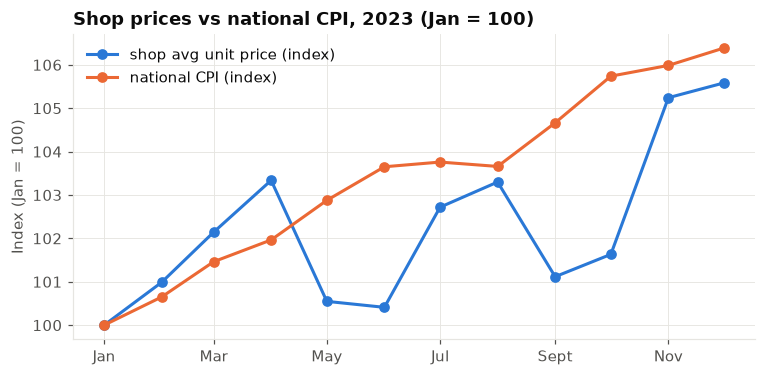

In [50]:
# cpi prep
c23 = cpi[(cpi.Period.dt.year == 2023)].set_index("Period").Value

# shopprice index
pidx = shop.assign(M=shop.Date.dt.to_period("M").dt.to_timestamp()).groupby(["M", "Product"]).UnitPrice.mean().unstack()
pidx = pidx / pidx.loc["2023-01-01"] * 100; basket = pidx.mean(axis=1)

# comparison table
cmpt = pd.DataFrame({"Shop price index (Jan=100)": basket, "CPI (Jan=100)": c23 / c23.iloc[0] * 100}) 
print(cmpt.round(1))

# plot + stats
fig, ax = plt.subplots(figsize=(8, 3.6)) 
ax.plot(
    cmpt.index, 
    cmpt.iloc[:, 0], 
    color=BLUE, lw=2, 
    marker="o", 
    label="shop avg unit price (index)"
) 
ax.plot(
    cmpt.index, 
    cmpt.iloc[:, 1], 
    color=ORANGE, 
    lw=2, 
    marker="o", 
    label="national CPI (index)"
)
ax.legend(frameon=False) 
ax.set_title("Shop prices vs national CPI, 2023 (Jan = 100)")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b")) 
ax.set_ylabel("Index (Jan = 100)")

print(
    "Spearman shop price index vs CPI:", 
    stats.spearmanr(cmpt.iloc[:, 0], cmpt.iloc[:, 1])
)
slope = np.polyfit(np.arange(12), np.log(cmpt.iloc[:, 0]), 1)[0] 
print(f"shop price drift: {(np.exp(slope*11)-1)*100:.1f}% over Jan->Dec (log-linear fit) vs CPI {(cmpt.iloc[-1,1]/100-1)*100:.1f}%")
print(
    "2023 annual inflation range:", 
    inflation[inflation.Period.dt.year == 2023]["Annual Change (%)"].agg(["min", "max"]).round(2).to_dict()
)
within = shop.groupby("Product").apply(lambda g: stats.spearmanr(g.Date.map(pd.Timestamp.toordinal), g.UnitPrice)[0]).round(3) 
print("within-product price vs date Spearman:\n", within)

### Top five findings
1. **Activity collapses after April:** 

Jan-Apr holds 84% of all orders (about 299 orders/month, 167-188 active customers) versus about 28 orders/month and 21-34 customers from May to December. Average order value stays flat (KES 122-182), so this is lost volume, not smaller baskets.

2. **Three products carry 60% of revenue:**

Eggs, cooking oil and sanitary towels are 34% of orders but 60% of revenue. Orders are spread evenly across the ten products (8-12% each), so revenue rank follows unit price (Spearman 0.66 between price and order count, p = 0.04).

3. **Kajiado over-indexes, Nairobi under-indexes:**

Nairobi county has 55% of the three counties' population but 47% of orders. Kajiado (Kitengela + Rongai) has 14% of the population and 22% of orders: 2.8 orders per 10k residents versus 1.5 in Nairobi. This depends on mapping Rongai to Kajiado.(Ongata Rongai)

4. **Premium customers pay the least for the same product:**

Relative to the product's median price, Premium customers pay about 7% below, Regular about 2% below and Budget about 2% above (Kruskal-Wallis p < 0.001). Premium is only 9.7% of customers. This looks like discounting or a mis-labelled tier, not a price premium.

5. **Shop prices lag inflation:**
Within-product prices are essentially flat over 2023 (Spearman with date below 0.18 for every product); the basket price index rose about 3% Jan to Dec against CPI +6.4% (inflation 6.6-9.2%). The CPI link is weak (rho 0.57, p = 0.055, 12 monthly points), so treat it as a direction, not a proof.
